In [1]:
import pandas as pd
from pathlib import Path

# Membaca dataset var1402
file_path = "../data/raw/bps/2026-10-20/sdg3_3_8_1_a_v1402.csv"

# Memeriksa apakah file ditemukan
print("File ditemukan:", Path(file_path).exists())

# Membaca dataset
df = pd.read_csv(file_path)

# Menampilkan 5 baris pertama
df.head()

File ditemukan: True


,var_id,wilayah_id,wilayah,turvar_id,turvar,tahun_id,tahun,periode_id,periode,nilai,satuan
0,1402,1100,ACEH,0,Tidak ada,115,2015,0,Tahun,3.09,Persen
1,1402,1100,ACEH,0,Tidak ada,116,2016,0,Tahun,2.86,Persen
2,1402,1100,ACEH,0,Tidak ada,117,2017,0,Tahun,3.62,Persen
3,1402,1100,ACEH,0,Tidak ada,118,2018,0,Tahun,4.53,Persen
4,1402,1100,ACEH,0,Tidak ada,119,2019,0,Tahun,4.36,Persen


In [2]:
# Melihat informasi dataset
print("Ukuran dataset:", df.shape)

print("\nDaftar kolom:")
print(df.columns.tolist())

print("\nDaftar seri (turvar):")
print(df[["turvar_id", "turvar"]].drop_duplicates())

print("\nRentang tahun:")
print(df["tahun"].min(), "-", df["tahun"].max())

print("\nJumlah wilayah:")
print(df["wilayah"].nunique())

Ukuran dataset: (393, 11)

Daftar kolom:
['var_id', 'wilayah_id', 'wilayah', 'turvar_id', 'turvar', 'tahun_id', 'tahun', 'periode_id', 'periode', 'nilai', 'satuan']

Daftar seri (turvar):
   turvar_id     turvar
0          0  Tidak ada

Rentang tahun:
2015 - 2025

Jumlah wilayah:
39


In [3]:
# Statistik deskriptif nilai indikator
statistik_umum = df["nilai"].describe()

print(statistik_umum)

count    393.000000
mean       5.121552
std        1.585249
min        1.390000
25%        4.080000
50%        4.930000
75%        6.060000
max       10.210000
Name: nilai, dtype: float64


In [4]:
# Memisahkan data provinsi dari agregat Indonesia
df_provinsi = df[df["wilayah_id"] != 9999].copy()

# Menghitung statistik deskriptif per provinsi
statistik_provinsi = (
    df_provinsi.groupby("wilayah")["nilai"]
    .agg(
        jumlah_data="count",
        rata_rata="mean",
        median="median",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .round(2)
    .reset_index()
)

statistik_provinsi

,wilayah,jumlah_data,rata_rata,median,standar_deviasi,minimum,maksimum
0,ACEH,11,4.60,4.36,1.20,2.86,6.83
1,BALI,11,3.05,2.96,0.76,2.04,4.36
2,BANTEN,11,5.18,4.74,1.05,4.12,7.00
3,BENGKULU,11,5.34,5.33,0.62,4.49,6.35
4,DI YOGYAKARTA,11,4.50,4.32,1.08,3.02,7.48
5,DKI JAKARTA,11,2.98,3.08,0.65,1.56,3.93
6,GORONTALO,11,7.69,7.89,1.05,6.03,8.89
7,JAMBI,11,4.93,4.66,0.77,3.85,6.56
8,JAWA BARAT,11,5.12,5.12,0.84,3.86,6.62
9,JAWA TENGAH,11,5.67,5.43,1.08,4.44,8.28


<Figure size 1600x700 with 0 Axes>

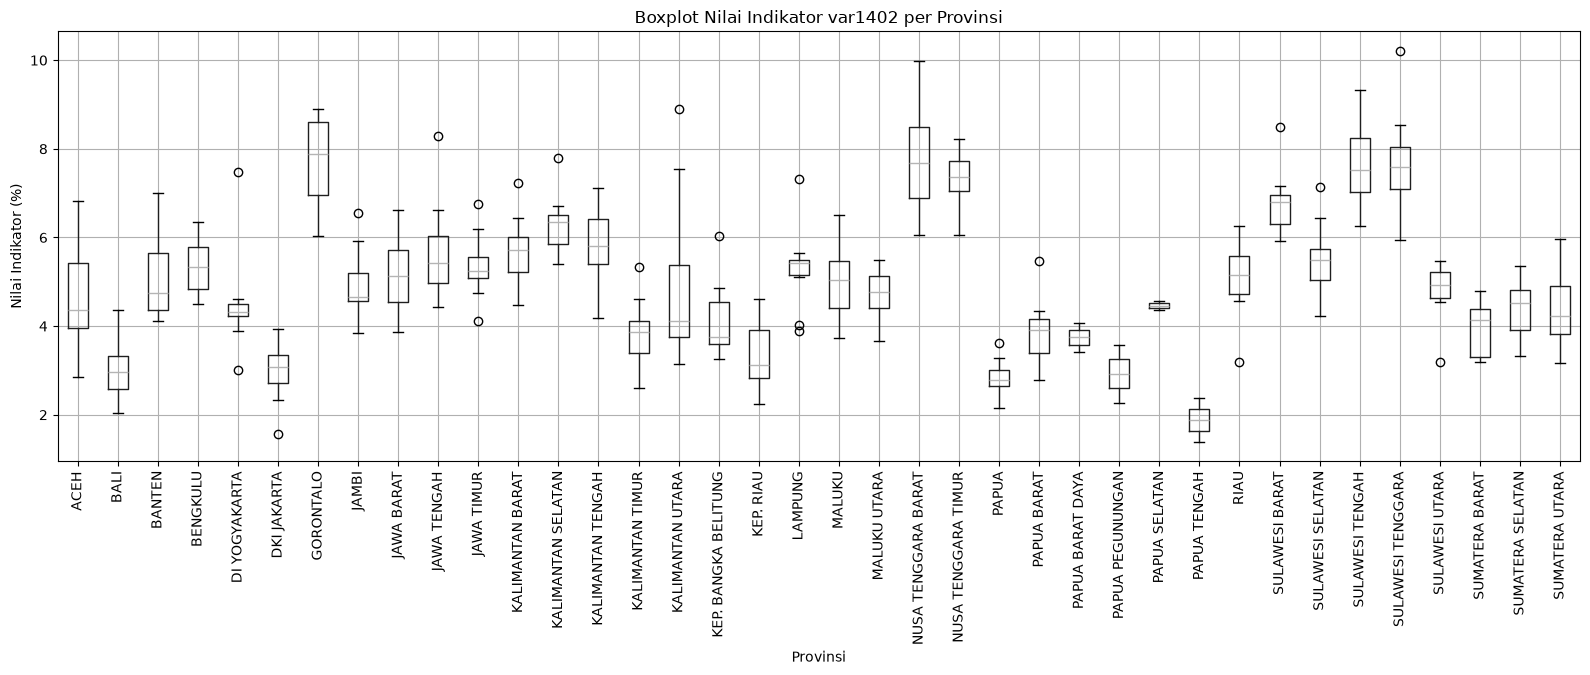

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

df_provinsi.boxplot(
    column="nilai",
    by="wilayah",
    figsize=(16, 7),
    rot=90
)

plt.title("Boxplot Nilai Indikator var1402 per Provinsi")
plt.suptitle("")
plt.xlabel("Provinsi")
plt.ylabel("Nilai Indikator (%)")
plt.tight_layout()

plt.show()

<Figure size 1600x700 with 0 Axes>

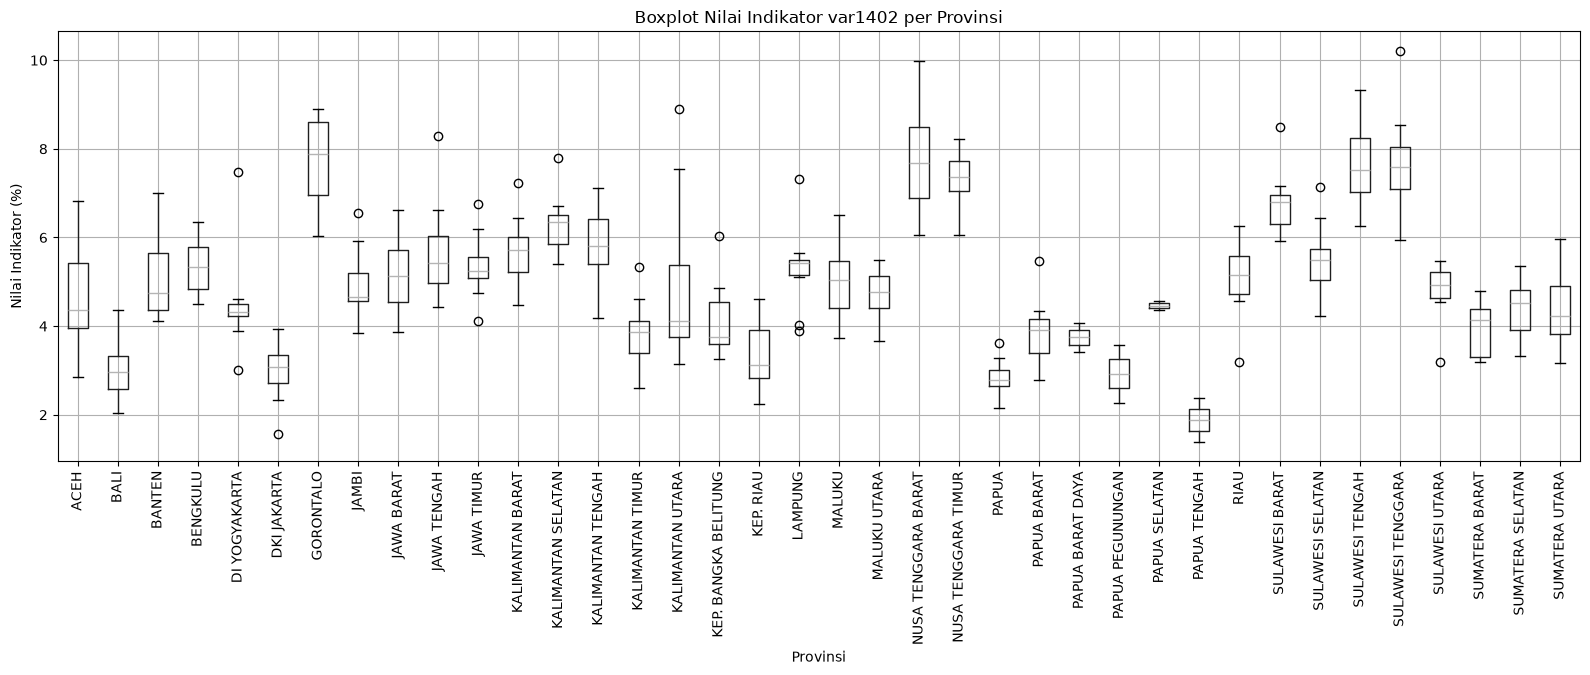

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

# Membuat folder jika belum tersedia
folder_gambar = Path("../reports/gambar")
folder_gambar.mkdir(parents=True, exist_ok=True)

# Membuat boxplot
plt.figure(figsize=(16, 7))

df_provinsi.boxplot(
    column="nilai",
    by="wilayah",
    figsize=(16, 7),
    rot=90
)

plt.title("Boxplot Nilai Indikator var1402 per Provinsi")
plt.suptitle("")
plt.xlabel("Provinsi")
plt.ylabel("Nilai Indikator (%)")
plt.tight_layout()

# Menyimpan grafik
plt.savefig(
    folder_gambar / "boxplot_var1402.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Mendeteksi calon anomali menggunakan IQR per provinsi

hasil_anomali = []

for wilayah, grup in df_provinsi.groupby("wilayah"):

    # Provinsi dengan kurang dari 4 data tidak diperiksa
    if len(grup) < 4:
        continue

    q1 = grup["nilai"].quantile(0.25)
    q3 = grup["nilai"].quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    # Mengambil nilai yang berada di luar batas IQR
    calon = grup[
        (grup["nilai"] < batas_bawah) |
        (grup["nilai"] > batas_atas)
    ]

    for _, baris in calon.iterrows():
        hasil_anomali.append({
            "wilayah": wilayah,
            "tahun": baris["tahun"],
            "nilai": baris["nilai"],
            "batas_bawah": round(batas_bawah, 2),
            "batas_atas": round(batas_atas, 2),
            "alasan": "Nilai berada di luar batas IQR 1.5"
        })

# Mengubah hasil menjadi DataFrame
df_anomali = pd.DataFrame(hasil_anomali)

df_anomali

,wilayah,tahun,nilai,batas_bawah,batas_atas,alasan
0,DI YOGYAKARTA,2021,3.02,3.78,4.94,Nilai berada di luar batas IQR 1.5
1,DI YOGYAKARTA,2022,7.48,3.78,4.94,Nilai berada di luar batas IQR 1.5
2,DKI JAKARTA,2022,1.56,1.76,4.30,Nilai berada di luar batas IQR 1.5
3,JAMBI,2022,6.56,3.64,6.12,Nilai berada di luar batas IQR 1.5
4,JAWA TENGAH,2021,8.28,3.39,7.61,Nilai berada di luar batas IQR 1.5
5,JAWA TIMUR,2016,4.11,4.35,6.29,Nilai berada di luar batas IQR 1.5
6,JAWA TIMUR,2021,6.75,4.35,6.29,Nilai berada di luar batas IQR 1.5
7,KALIMANTAN BARAT,2023,7.23,4.04,7.19,Nilai berada di luar batas IQR 1.5
8,KALIMANTAN SELATAN,2015,7.80,4.89,7.47,Nilai berada di luar batas IQR 1.5
9,KALIMANTAN TIMUR,2022,5.34,2.34,5.17,Nilai berada di luar batas IQR 1.5


In [8]:
from pathlib import Path

# Membuat folder reports jika belum tersedia
folder_laporan = Path("../reports")
folder_laporan.mkdir(parents=True, exist_ok=True)

# Menyimpan daftar calon anomali
df_anomali.to_csv(
    folder_laporan / "calon_anomali_var1402.csv",
    index=False
)

print("Jumlah calon anomali:", len(df_anomali))
print("File berhasil disimpan!")

Jumlah calon anomali: 22
File berhasil disimpan!


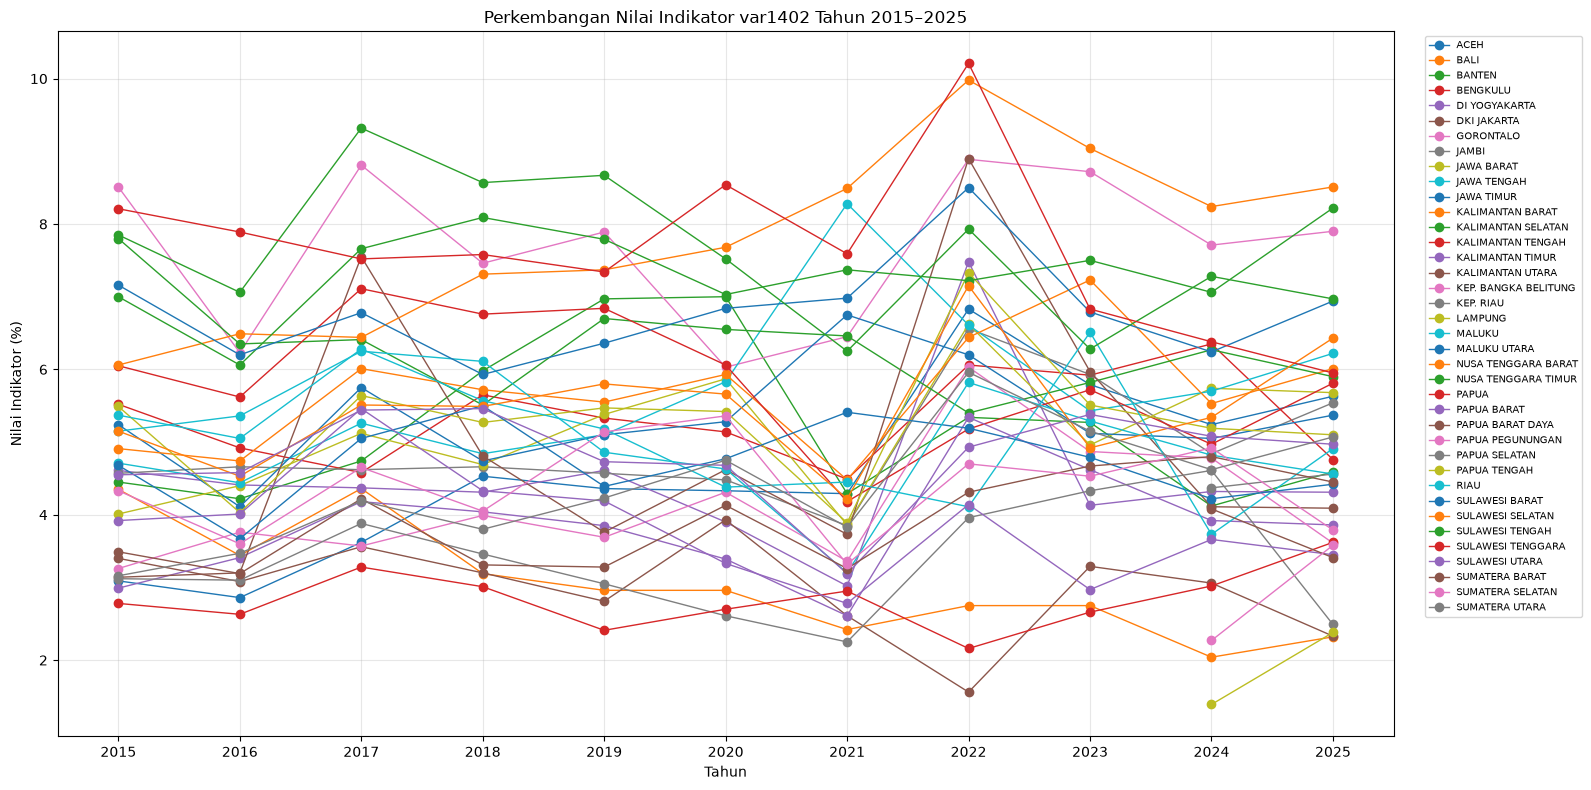

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

# Membuat garis untuk setiap provinsi
for wilayah, grup in df_provinsi.groupby("wilayah"):
    grup = grup.sort_values("tahun")

    plt.plot(
        grup["tahun"],
        grup["nilai"],
        marker="o",
        linewidth=1,
        label=wilayah
    )

plt.title("Perkembangan Nilai Indikator var1402 Tahun 2015–2025")
plt.xlabel("Tahun")
plt.ylabel("Nilai Indikator (%)")
plt.xticks(range(2015, 2026))
plt.grid(True, alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=7
)

plt.tight_layout()
plt.show()

In [10]:
plt.savefig(
    "../reports/gambar/time_series_var1402.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [11]:
# Membaca dataset var2279

df2279 = pd.read_csv(
    "../data/raw/bps/2026-10-20/sdg3_3_8_2_a_v2279.csv"
)

print("Ukuran dataset:", df2279.shape)

df2279.head()

Ukuran dataset: (152, 11)


,var_id,wilayah_id,wilayah,turvar_id,turvar,tahun_id,tahun,periode_id,periode,nilai,satuan
0,2279,1100,ACEH,0,Tidak ada,122,2022,0,Tahun,97.05,Persen
1,2279,1100,ACEH,0,Tidak ada,123,2023,0,Tahun,96.87,Persen
2,2279,1100,ACEH,0,Tidak ada,124,2024,0,Tahun,97.19,Persen
3,2279,1100,ACEH,0,Tidak ada,125,2025,0,Tahun,98.18,Persen
4,2279,1200,SUMATERA UTARA,0,Tidak ada,122,2022,0,Tahun,56.30,Persen


In [12]:
# Pemeriksaan struktur dataset var2279

print("Ukuran dataset:", df2279.shape)

print("\nDaftar kolom:")
print(df2279.columns.tolist())

print("\nDaftar seri:")
print(df2279[["turvar_id", "turvar"]].drop_duplicates())

print("\nRentang tahun:")
print(df2279["tahun"].min(), "-", df2279["tahun"].max())

print("\nJumlah wilayah:")
print(df2279["wilayah"].nunique())

print("\nJumlah data per tahun:")
print(df2279.groupby("tahun").size())

Ukuran dataset: (152, 11)

Daftar kolom:
['var_id', 'wilayah_id', 'wilayah', 'turvar_id', 'turvar', 'tahun_id', 'tahun', 'periode_id', 'periode', 'nilai', 'satuan']

Daftar seri:
   turvar_id     turvar
0          0  Tidak ada

Rentang tahun:
2022 - 2025

Jumlah wilayah:
39

Jumlah data per tahun:
tahun
2022    35
2023    39
2024    39
2025    39
dtype: int64


In [13]:
# Memisahkan agregat Indonesia dari data provinsi
df2279_provinsi = df2279[
    df2279["wilayah_id"] != 9999
].copy()

# Menghitung statistik deskriptif per provinsi
statistik2279 = (
    df2279_provinsi.groupby("wilayah")["nilai"]
    .agg(
        jumlah_data="count",
        rata_rata="mean",
        median="median",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .round(2)
    .reset_index()
)

statistik2279

,wilayah,jumlah_data,rata_rata,median,standar_deviasi,minimum,maksimum
0,ACEH,4,97.32,97.12,0.59,96.87,98.18
1,BALI,4,86.69,87.18,2.69,83.24,89.15
2,BANTEN,4,69.94,69.66,3.94,65.92,74.49
3,BENGKULU,4,69.90,70.10,5.55,63.18,76.20
4,DI YOGYAKARTA,4,84.93,84.49,3.37,81.47,89.27
5,DKI JAKARTA,4,89.03,89.20,2.39,86.04,91.69
6,GORONTALO,4,84.61,85.66,3.84,79.37,87.74
7,JAMBI,4,56.64,56.03,3.57,53.49,61.04
8,JAWA BARAT,4,66.57,66.84,3.90,61.98,70.62
9,JAWA TENGAH,4,70.16,69.99,2.28,67.70,72.96


<Figure size 1600x700 with 0 Axes>

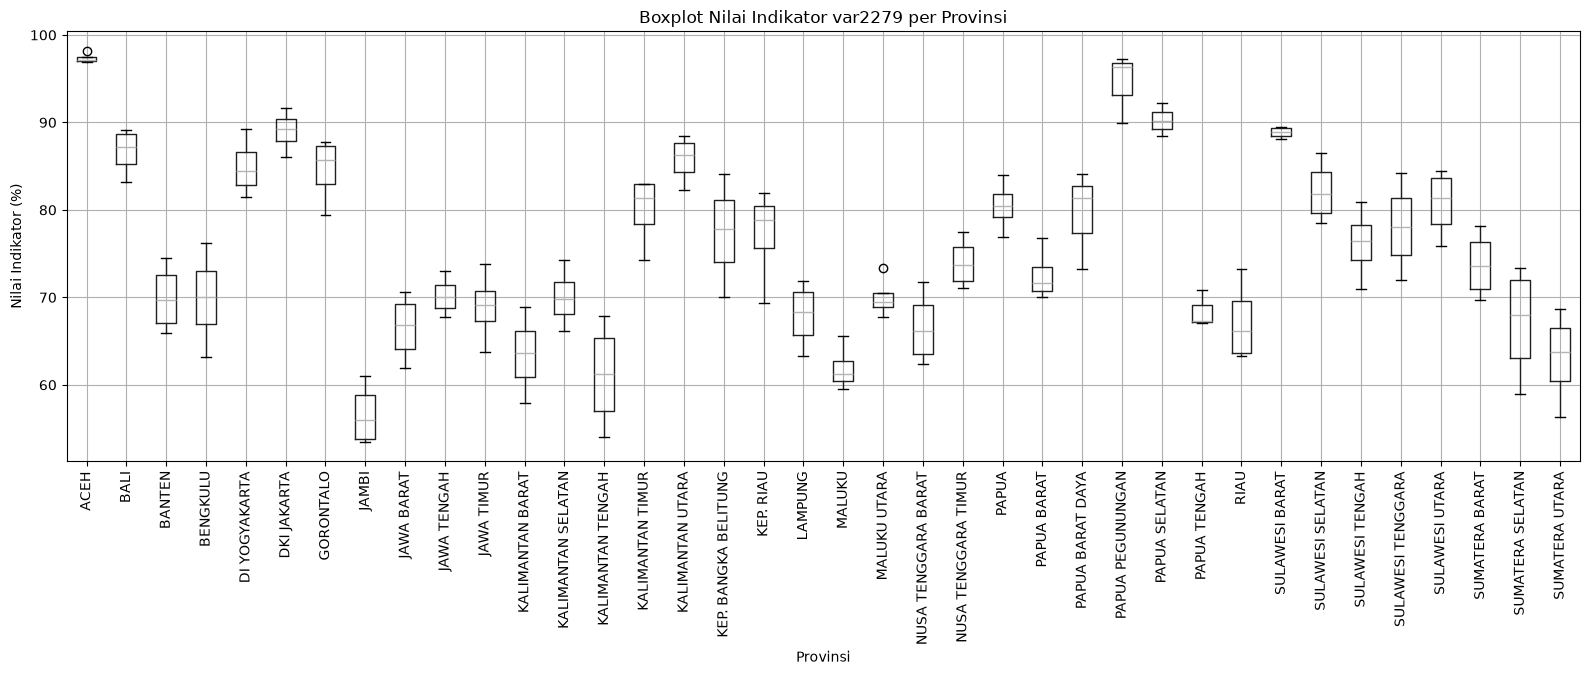

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

df2279_provinsi.boxplot(
    column="nilai",
    by="wilayah",
    figsize=(16, 7),
    rot=90
)

plt.title("Boxplot Nilai Indikator var2279 per Provinsi")
plt.suptitle("")
plt.xlabel("Provinsi")
plt.ylabel("Nilai Indikator (%)")
plt.tight_layout()

plt.show()

<Figure size 1600x700 with 0 Axes>

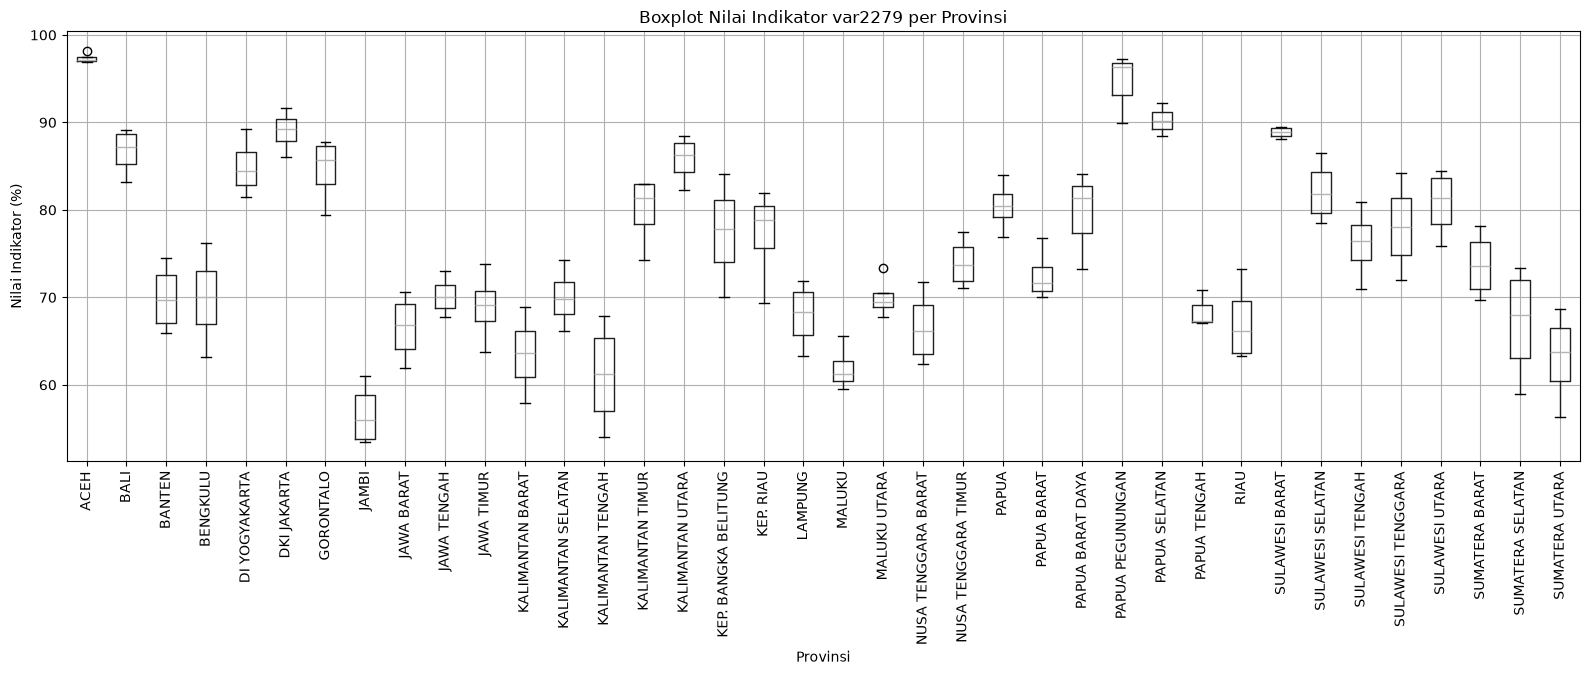

In [15]:
plt.figure(figsize=(16, 7))

df2279_provinsi.boxplot(
    column="nilai",
    by="wilayah",
    figsize=(16, 7),
    rot=90
)

plt.title("Boxplot Nilai Indikator var2279 per Provinsi")
plt.suptitle("")
plt.xlabel("Provinsi")
plt.ylabel("Nilai Indikator (%)")
plt.tight_layout()

plt.savefig(
    "../reports/gambar/boxplot_var2279.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
hasil_anomali2279 = []

for tahun, grup in df2279_provinsi.groupby("tahun"):
    q1 = grup["nilai"].quantile(0.25)
    q3 = grup["nilai"].quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    calon = grup[
        (grup["nilai"] < batas_bawah) |
        (grup["nilai"] > batas_atas)
    ]

    for _, baris in calon.iterrows():
        hasil_anomali2279.append({
            "provinsi": baris["wilayah"],
            "tahun": tahun,
            "nilai": baris["nilai"],
            "batas_bawah": round(batas_bawah, 2),
            "batas_atas": round(batas_atas, 2),
            "alasan": "Nilai berada di luar batas IQR pada tahun yang sama"
        })

df_anomali2279 = pd.DataFrame(hasil_anomali2279)

print("Jumlah calon anomali:", len(df_anomali2279))
display(df_anomali2279)

Jumlah calon anomali: 0


""


In [17]:
df_anomali2279.to_csv(
    "../reports/calon_anomali_var2279.csv",
    index=False
)

print("Hasil calon anomali var2279 berhasil disimpan.")

Hasil calon anomali var2279 berhasil disimpan.


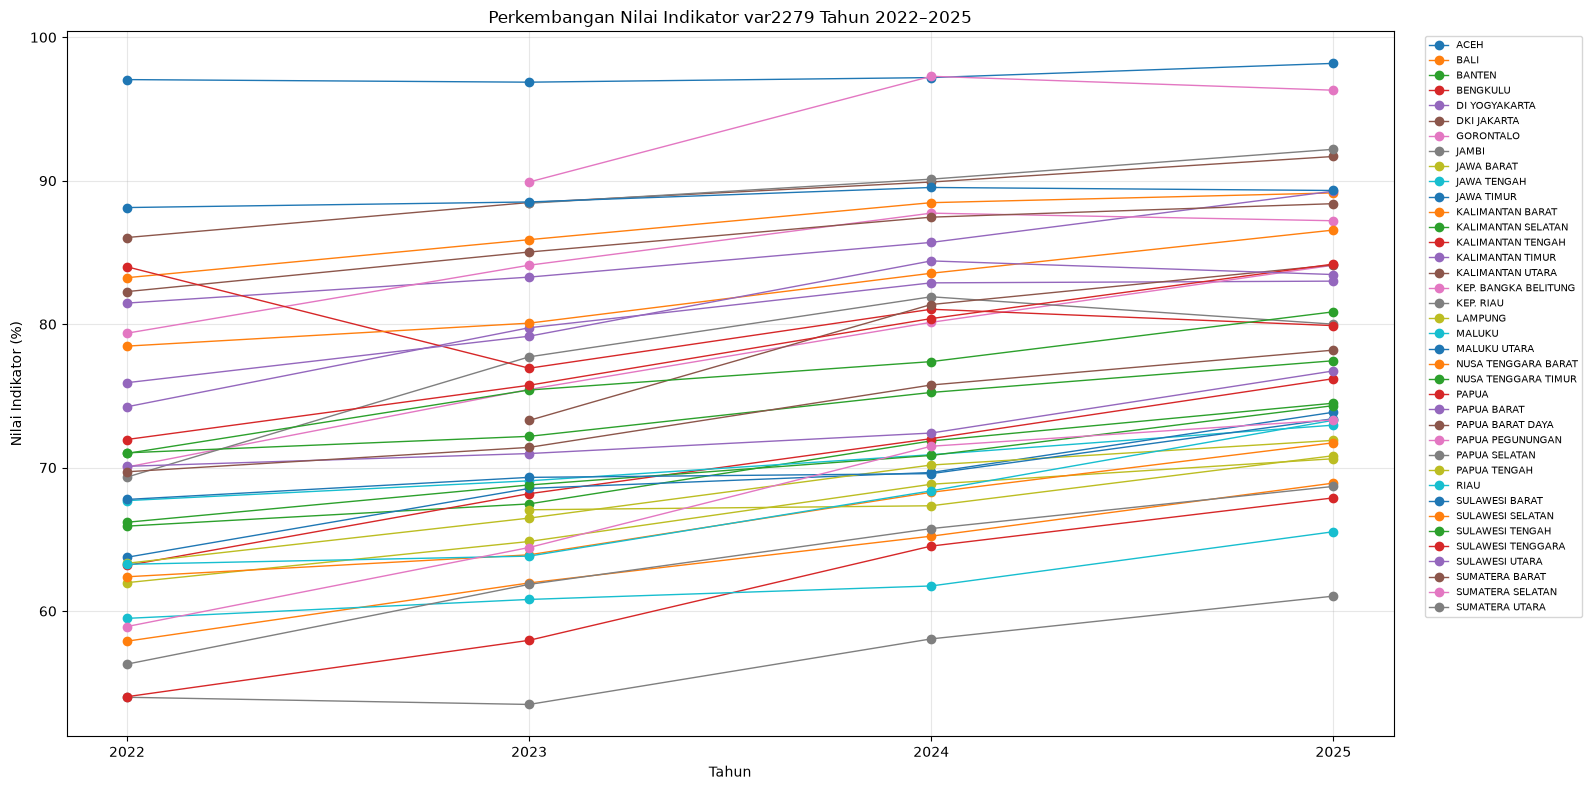

In [18]:
plt.figure(figsize=(16, 8))

for wilayah, grup in df2279_provinsi.groupby("wilayah"):
    grup = grup.sort_values("tahun")

    plt.plot(
        grup["tahun"],
        grup["nilai"],
        marker="o",
        linewidth=1,
        label=wilayah
    )

plt.title("Perkembangan Nilai Indikator var2279 Tahun 2022–2025")
plt.xlabel("Tahun")
plt.ylabel("Nilai Indikator (%)")
plt.xticks([2022, 2023, 2024, 2025])
plt.grid(True, alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=7
)

plt.tight_layout()

plt.savefig(
    "../reports/gambar/time_series_var2279.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
df1477 = pd.read_csv(
    "../data/raw/bps/2026-10-20/sdg3_3_c_1_v1477.csv"
)

print("Ukuran dataset:", df1477.shape)
print("\nNama kolom:")
print(df1477.columns.tolist())

print("\nDaftar kategori:")
display(
    df1477[["turvar_id", "turvar"]]
    .drop_duplicates()
    .sort_values("turvar_id")
)

print("\nJumlah data per tahun:")
print(df1477.groupby("tahun").size())

print("\nJumlah provinsi:")
print(df1477["wilayah"].nunique())

Ukuran dataset: (926, 11)

Nama kolom:
['var_id', 'wilayah_id', 'wilayah', 'turvar_id', 'turvar', 'tahun_id', 'tahun', 'periode_id', 'periode', 'nilai', 'satuan']

Daftar kategori:


,turvar_id,turvar
0,1173,Dokter Umum
3,1174,Dokter Gigi
6,1175,Perawat
9,1176,Bidan
12,1177,Farmasi
15,1178,Kesehatan Masyarakat
18,1179,Kesehatan Lingkungan
21,1180,Gizi
24,1181,Ahli Teknologi Laboratorium Medik
26,1182,Pekarya



Jumlah data per tahun:
tahun
2016    340
2017    306
2018    280
dtype: int64

Jumlah provinsi:
35


In [20]:
# Pisahkan data provinsi dari agregat Indonesia
df1477_provinsi = df1477[
    df1477["wilayah_id"] != 9999
].copy()

# Hitung statistik setiap kategori pada setiap provinsi
statistik1477 = (
    df1477_provinsi
    .groupby(["turvar", "wilayah"])["nilai"]
    .agg(
        jumlah_data="count",
        rata_rata="mean",
        median="median",
        standar_deviasi="std",
        minimum="min",
        maksimum="max"
    )
    .round(2)
    .reset_index()
)

print("Jumlah data provinsi:", len(df1477_provinsi))
print("Jumlah kategori:", df1477_provinsi["turvar"].nunique())
print("Jumlah provinsi:", df1477_provinsi["wilayah"].nunique())

display(statistik1477)

Jumlah data provinsi: 918
Jumlah kategori: 10
Jumlah provinsi: 34


,turvar,wilayah,jumlah_data,rata_rata,median,standar_deviasi,minimum,maksimum
0,Ahli Teknologi Laboratorium Medik,ACEH,2,12.50,12.5,0.71,12,13
1,Ahli Teknologi Laboratorium Medik,BALI,2,8.00,8.0,1.41,7,9
2,Ahli Teknologi Laboratorium Medik,BANTEN,2,5.00,5.0,0.00,5,5
3,Ahli Teknologi Laboratorium Medik,BENGKULU,2,10.00,10.0,1.41,9,11
4,Ahli Teknologi Laboratorium Medik,DI YOGYAKARTA,2,15.00,15.0,0.00,15,15
...,...,...,...,...,...,...,...,...
335,Perawat,SULAWESI TENGGARA,3,165.67,180.0,49.10,111,206
336,Perawat,SULAWESI UTARA,3,197.67,205.0,52.39,142,246
337,Perawat,SUMATERA BARAT,3,129.67,130.0,15.50,114,145
338,Perawat,SUMATERA SELATAN,3,123.33,120.0,12.34,113,137


In [21]:
statistik1477.to_csv(
    "../reports/statistik_var1477.csv",
    index=False
)

print("Statistik var1477 berhasil disimpan.")

Statistik var1477 berhasil disimpan.


<Figure size 1400x700 with 0 Axes>

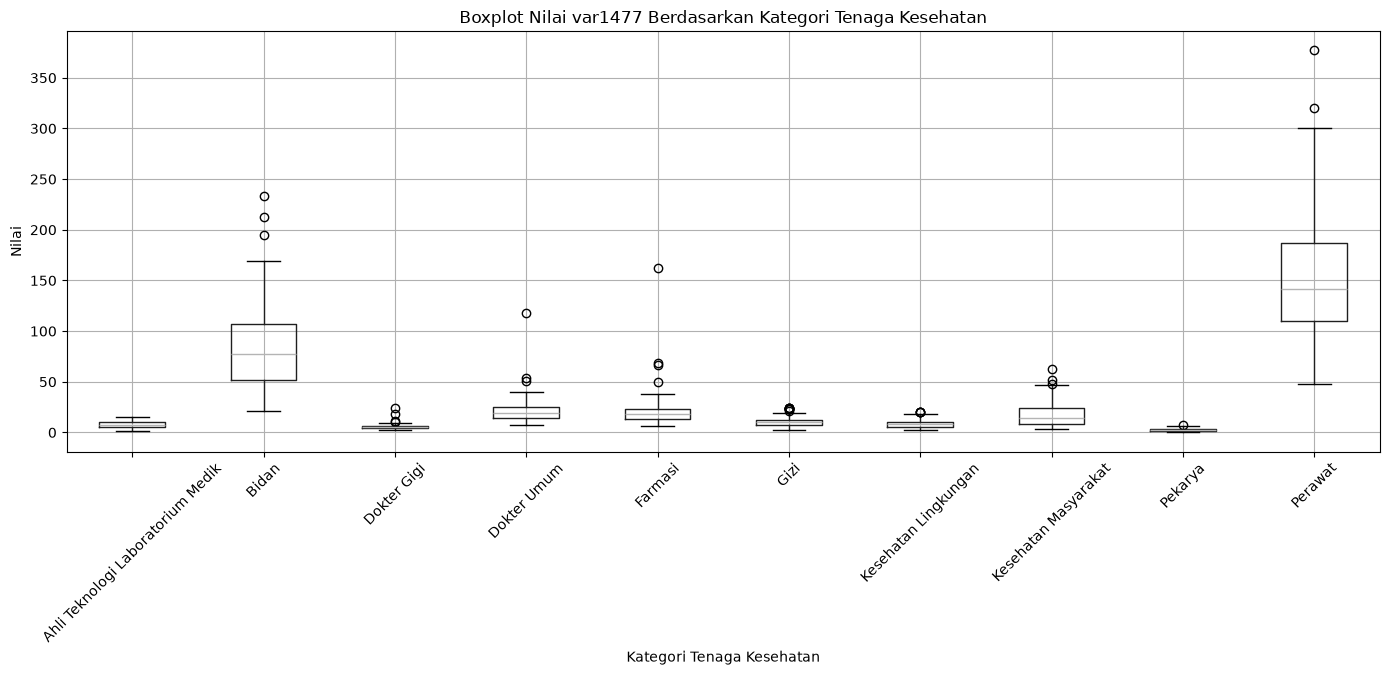

In [22]:
plt.figure(figsize=(14, 7))

df1477_provinsi.boxplot(
    column="nilai",
    by="turvar",
    rot=45,
    figsize=(14, 7)
)

plt.title("Boxplot Nilai var1477 Berdasarkan Kategori Tenaga Kesehatan")
plt.suptitle("")
plt.xlabel("Kategori Tenaga Kesehatan")
plt.ylabel("Nilai")
plt.tight_layout()

plt.savefig(
    "../reports/gambar/boxplot_var1477.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

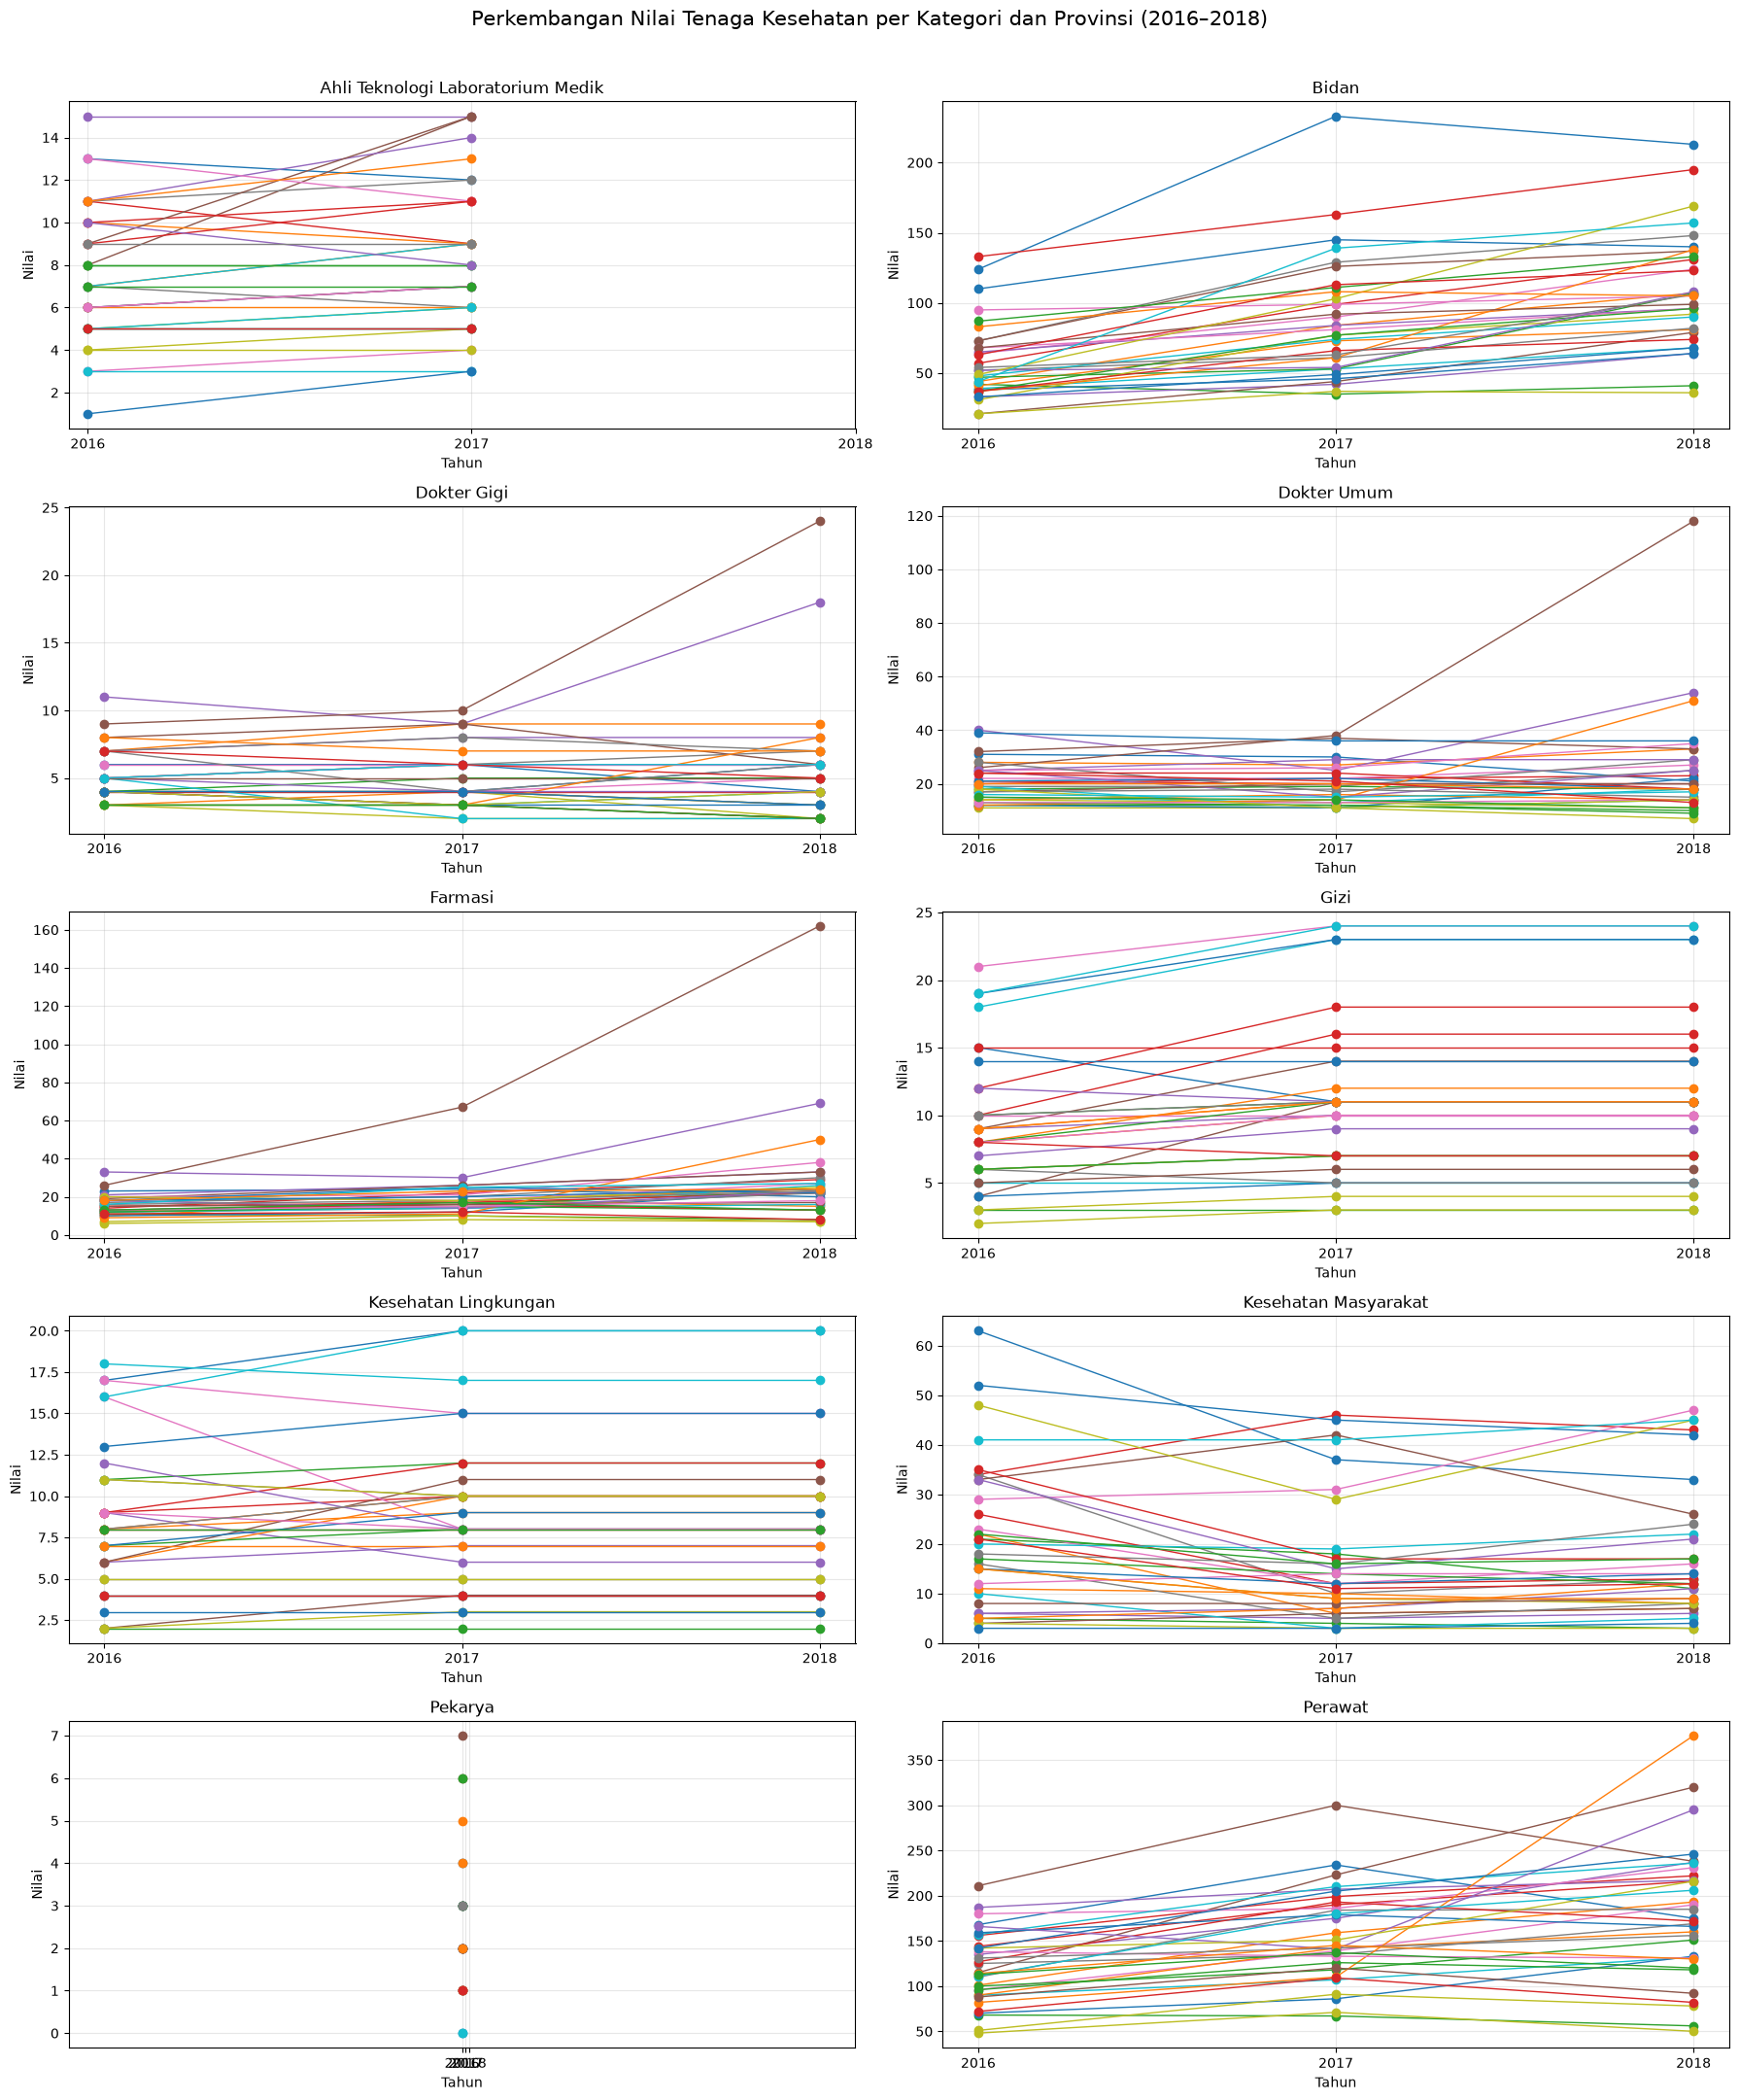

In [23]:
fig, axes = plt.subplots(5, 2, figsize=(18, 22))

kategori = sorted(df1477_provinsi["turvar"].unique())

for ax, nama_kategori in zip(axes.flatten(), kategori):
    data_kategori = df1477_provinsi[
        df1477_provinsi["turvar"] == nama_kategori
    ]

    for wilayah, grup in data_kategori.groupby("wilayah"):
        grup = grup.sort_values("tahun")

        ax.plot(
            grup["tahun"],
            grup["nilai"],
            marker="o",
            linewidth=1,
            label=wilayah
        )

    ax.set_title(nama_kategori)
    ax.set_xlabel("Tahun")
    ax.set_ylabel("Nilai")
    ax.set_xticks([2016, 2017, 2018])
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Perkembangan Nilai Tenaga Kesehatan per Kategori dan Provinsi (2016–2018)",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    "../reports/gambar/time_series_var1477.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
hasil_anomali1477 = []

for (kategori, tahun), grup in df1477_provinsi.groupby(
    ["turvar", "tahun"]
):
    if len(grup) < 4:
        continue

    q1 = grup["nilai"].quantile(0.25)
    q3 = grup["nilai"].quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    calon = grup[
        (grup["nilai"] < batas_bawah) |
        (grup["nilai"] > batas_atas)
    ]

    for _, baris in calon.iterrows():
        hasil_anomali1477.append({
            "kategori": kategori,
            "provinsi": baris["wilayah"],
            "tahun": tahun,
            "nilai": baris["nilai"],
            "batas_bawah": round(batas_bawah, 2),
            "batas_atas": round(batas_atas, 2),
            "alasan": "Nilai berada di luar batas IQR pada kategori dan tahun yang sama"
        })

df_anomali1477 = pd.DataFrame(hasil_anomali1477)

print("Jumlah calon anomali:", len(df_anomali1477))
display(df_anomali1477)

Jumlah calon anomali: 36


,kategori,provinsi,tahun,nilai,batas_bawah,batas_atas,alasan
0,Bidan,ACEH,2016,124,-6.38,112.62,Nilai berada di luar batas IQR pada kategori d...
1,Bidan,BENGKULU,2016,133,-6.38,112.62,Nilai berada di luar batas IQR pada kategori d...
2,Bidan,ACEH,2017,233,-20.75,183.25,Nilai berada di luar batas IQR pada kategori d...
3,Bidan,ACEH,2018,213,4.38,209.38,Nilai berada di luar batas IQR pada kategori d...
4,Dokter Gigi,DI YOGYAKARTA,2016,11,-0.12,10.88,Nilai berada di luar batas IQR pada kategori d...
5,Dokter Gigi,DKI JAKARTA,2018,24,-1.50,10.50,Nilai berada di luar batas IQR pada kategori d...
6,Dokter Gigi,DI YOGYAKARTA,2018,18,-1.50,10.50,Nilai berada di luar batas IQR pada kategori d...
7,Dokter Umum,DKI JAKARTA,2018,118,-7.75,50.25,Nilai berada di luar batas IQR pada kategori d...
8,Dokter Umum,DI YOGYAKARTA,2018,54,-7.75,50.25,Nilai berada di luar batas IQR pada kategori d...
9,Dokter Umum,NUSA TENGGARA BARAT,2018,51,-7.75,50.25,Nilai berada di luar batas IQR pada kategori d...


In [25]:
df_anomali1477.to_csv(
    "../reports/calon_anomali_var1477.csv",
    index=False
)

print("Hasil calon anomali var1477 berhasil disimpan.")

Hasil calon anomali var1477 berhasil disimpan.


In [26]:
ringkasan_anomali1477 = (
    df_anomali1477
    .groupby("kategori")
    .size()
    .reset_index(name="jumlah_calon_anomali")
    .sort_values("jumlah_calon_anomali", ascending=False)
)

display(ringkasan_anomali1477)

ringkasan_anomali1477.to_csv(
    "../reports/ringkasan_anomali_var1477.csv",
    index=False
)

,kategori,jumlah_calon_anomali
6,Kesehatan Masyarakat,9
3,Farmasi,5
4,Gizi,5
0,Bidan,4
5,Kesehatan Lingkungan,4
1,Dokter Gigi,3
2,Dokter Umum,3
8,Perawat,2
7,Pekarya,1


In [27]:
# Simpan statistik var1402
statistik_provinsi.to_csv(
    "../reports/statistik_var1402.csv",
    index=False
)

# Simpan statistik var2279
statistik2279.to_csv(
    "../reports/statistik_var2279.csv",
    index=False
)

print("Statistik var1402 dan var2279 berhasil disimpan.")

Statistik var1402 dan var2279 berhasil disimpan.


In [28]:
from pathlib import Path

folder_reports = Path("../reports")

print("ISI FOLDER REPORTS:\n")

for file in sorted(folder_reports.rglob("*")):
    if file.is_file():
        print(file.relative_to(folder_reports))

ISI FOLDER REPORTS:

calon_anomali_var1402.csv
calon_anomali_var1477.csv
calon_anomali_var2279.csv
gambar\boxplot_var1402.png
gambar\boxplot_var1477.png
gambar\boxplot_var2279.png
gambar\time_series_var1402.png
gambar\time_series_var1477.png
gambar\time_series_var2279.png
individu\124450092.md
individu\TEMPLATE.md
ringkasan_anomali_var1477.csv
statistik_var1402.csv
statistik_var1477.csv
statistik_var2279.csv
tim.md
